In [1]:
import pandas as pd
import numpy as np
from basin import *
from MultiAgent_DQ import *
import sys
sys.path.append('../')
from utils import *

In [2]:
# Parameters
t = 1
s = 0
r = 0.7
p = 0.2
epsilon = 0.1
d = 0.6
alpha = 0.3
bound = 1 / (1 - d)

In [3]:

def trim_q_by_strategy(q1, q2, s1, s2):
    """
    Trim q1 and q2 sequences based on their respective initial strategy orderings.
    Both sequences are cut to the same length, determined by when *either* violates
    its initial ordering — whichever lasts longer determines the trim point.
    
    Parameters
    ----------
    q1, q2 : pd.DataFrame or np.ndarray
        Time × features (Q-values). Must have same length along time axis.
    s1, s2 : str
        Strategies for q1 and q2, each one of {"AD","GT","AGT","AC"}.
        
    Returns
    -------
    q1_trimmed, q2_trimmed : same type as input
        Trimmed sequences up to the last timestep where both maintain initial ordering.
    """
    
    # Convert to numpy if DataFrames
    q1_arr = q1.values if hasattr(q1, "values") else np.asarray(q1)
    q2_arr = q2.values if hasattr(q2, "values") else np.asarray(q2)
    
    def ordering_sign(Q, strategy):
        """
        Compute sign of (defect - coop) according to strategy from a 2x2 Q-matrix or row pair.
        Positive sign → defect > coop, Negative → coop > defect.
        """
        delta = Q[1] - Q[0]
        if strategy in ["GT", "AC"]:
            delta = -delta
        return np.sign(delta)
    
    def valid_length(Q, strategy):
        """Return how long ordering stays consistent with the initial."""
        # Use first two timesteps as reference
        ref_sign = ordering_sign(Q[:2], strategy)
        last_valid_idx = 1
        for t in range(1, Q.shape[0]):
            cur_sign = ordering_sign(Q[t-1:t+1], strategy)
            if np.all(cur_sign == ref_sign):
                last_valid_idx = t
            else:
                break
        return last_valid_idx + 1  # inclusive index
    
    len1 = valid_length(q1_arr, s1)
    len2 = valid_length(q2_arr, s2)
    
    # Cut based on whichever lasts longer
    cut_len = min(len1, len2) 
    
    if hasattr(q1, "iloc"):
        return q1.iloc[:cut_len], q2.iloc[:cut_len]
    else:
        return q1_arr[:cut_len], q2_arr[:cut_len]


Using seed: 718723624
Running pair: (AD, AD)
DEBUG: Vector field parameters
epsilon = 0.1
func1 = QvaluesADvsAD
func2 = QvaluesADvsAD

Q1 from QvaluesADvsAD: [0.584625 0.379625]
Q2 from QvaluesADvsAD: [0.584625 0.379625]

Vector field TARGET: (0.2050, 0.2050)

Trajectory endpoint:
  Player 1 (x): 0.2050
  Player 2 (y): 0.2053
Running pair: (AD, GT)
DEBUG: Vector field parameters
epsilon = 0.1
func1 = QvaluesGTvsGT
func2 = QvaluesADvsAD

Q1 from QvaluesGTvsGT: [1.30682609 1.56943478]
Q2 from QvaluesADvsAD: [0.584625 0.379625]

Vector field TARGET: (-0.2626, 0.2050)

Trajectory endpoint:
  Player 1 (x): -0.0136
  Player 2 (y): 0.0050
Running pair: (AD, AGT)
DEBUG: Vector field parameters
epsilon = 0.1
func1 = QvaluesADvsAGT
func2 = QvaluesADvsAD

Q1 from QvaluesADvsAGT: [1.62809153 1.40219085]
Q2 from QvaluesADvsAD: [0.584625 0.379625]

Vector field TARGET: (0.2259, 0.2050)

Trajectory endpoint:
  Player 1 (x): 0.4896
  Player 2 (y): 0.2188
Running pair: (AD, AC)
DEBUG: Vector field para

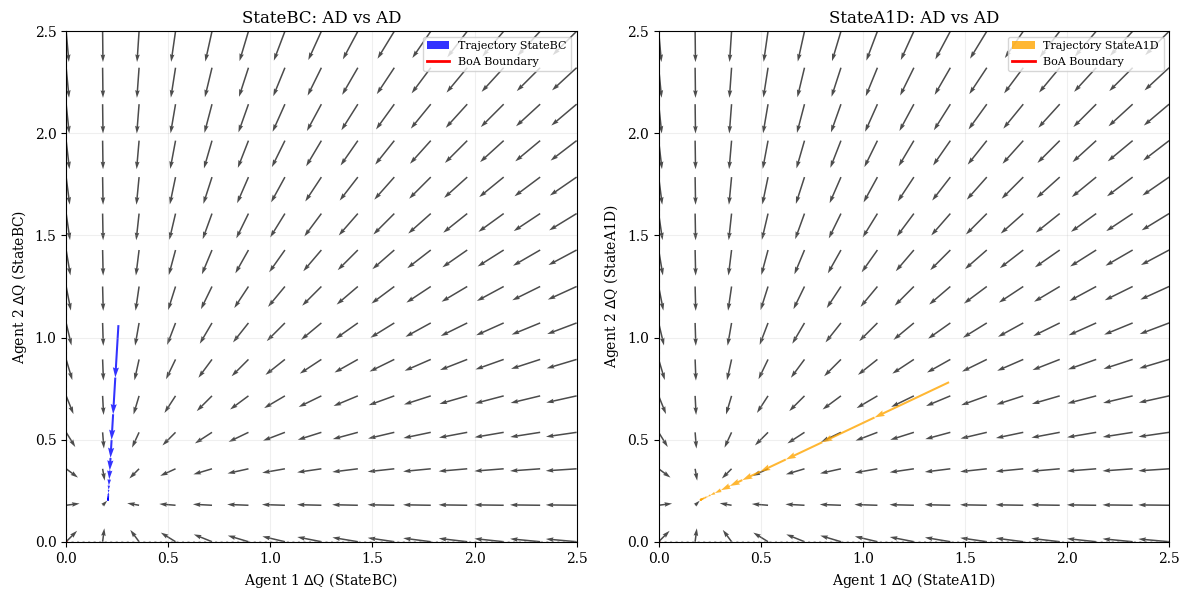

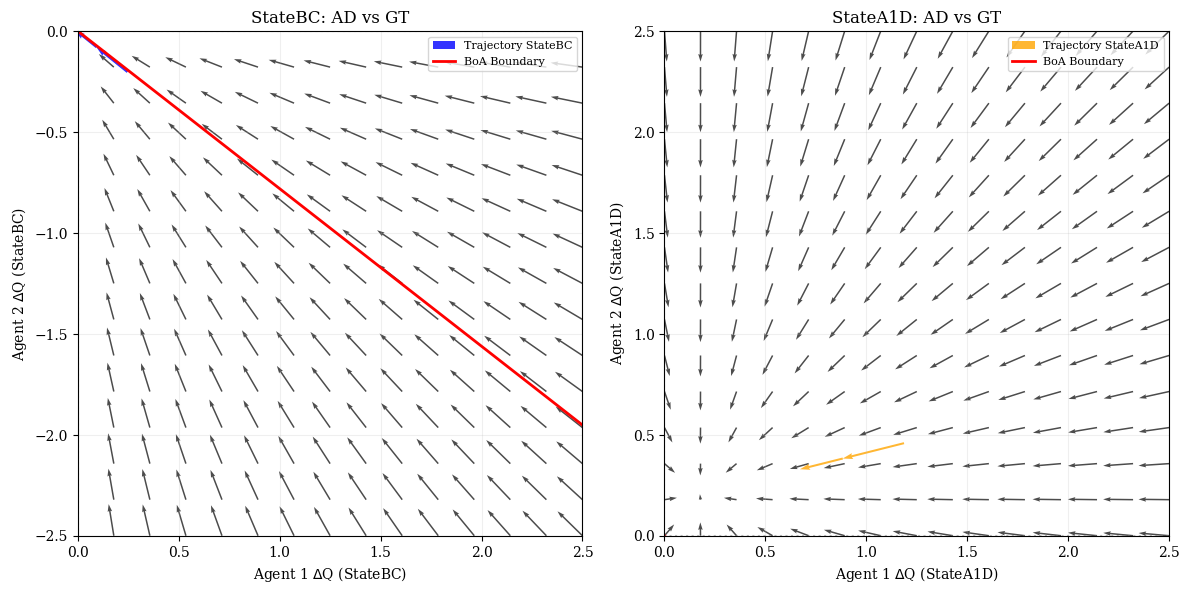

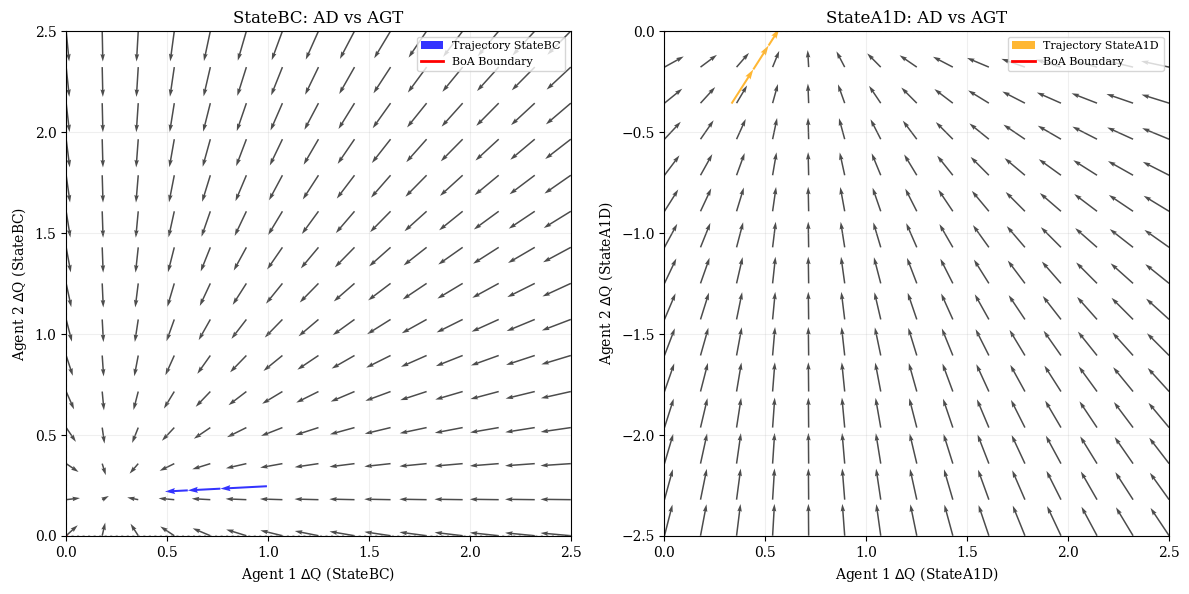

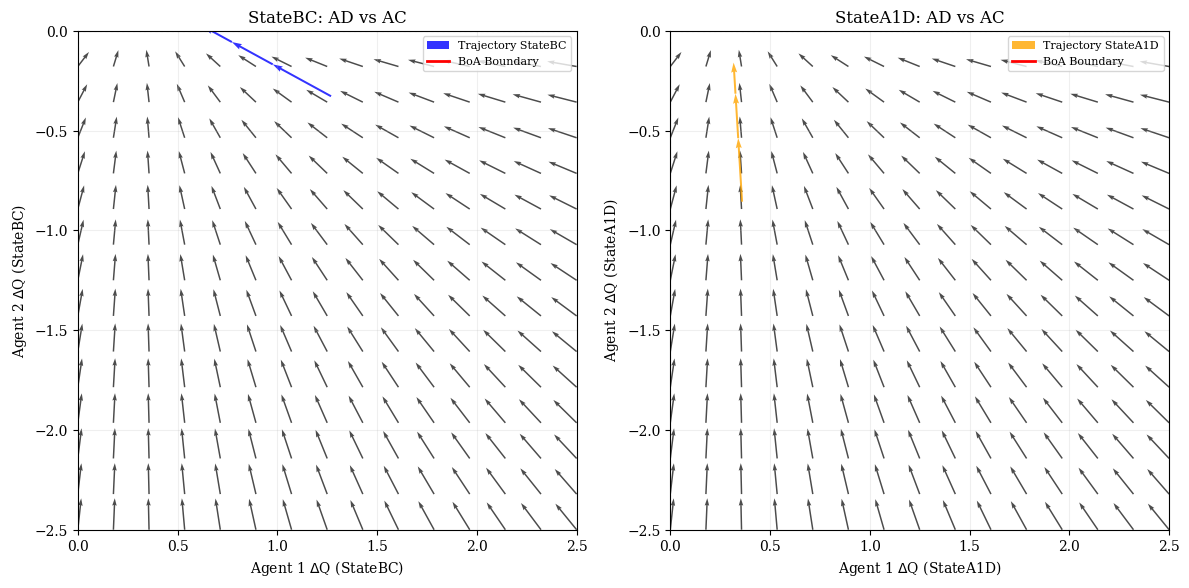

In [4]:
# Strategy pairs
strategy_pairs = [
    ("AD","AD"), ("AD","GT"), ("AD","AGT"), ("AD","AC"),
    #("GT","AD"), ("GT","GT"), ("GT","AGT"), ("GT","AC"),
    #("AGT","AD"), ("AGT","GT"), ("AGT","AGT"), ("AGT","AC"),
    #("AC","AD"), ("AC","GT"), ("AC","AGT"), 
    #("AC","AC")
]
stop_when_cross = True
# Map opponent strategy to function
func_map = {
    "AD": QvaluesADvsAD,
    "GT": QvaluesGTvsGT,
    "AGT": QvaluesADvsAGT,
    "AC": QvaluesADvsAC
}
randomseeds = np.random.randint(1, 1020131031, size=1)  # 5 is exclusive

for seed in randomseeds:
    np.random.seed(seed)
    print(f"Using seed: {seed}")
    for s1, s2 in strategy_pairs:
        print(f"Running pair: ({s1}, {s2})")

        # Initialize algorithm with fixed strategy pair
        algo = Algorithm(
            e=epsilon, lambda_val=0, alpha=alpha, delta=d,
            init_mode='fixed', tolerance=1e-10, 
            M=5, strategy1=s1, strategy2=s2,
            t=t, r=r, p=p, s=s,  # Pass payoff parameters
            verbose=False
        )

        # Run the algorithm
        q1_history_per_sample_algo, q2_history_per_sample_algo, batch_times_algo, timeout_out, timeout_vi = algo.run()

        # Pick a sample
        exp = np.random.randint(0, 5)
        q1 = convert_dict_to_mean_df(q1_history_per_sample_algo, mean=False)[exp]
        q2 = convert_dict_to_mean_df(q2_history_per_sample_algo, mean=False)[exp]
        if stop_when_cross:
            q1, q2 = trim_q_by_strategy(q1, q2, s1, s2)
        func1 = func_map[s2]  # x-component uses opponent strategy s2
        func2 = func_map[s1]  # y-component uses same opponent strategy
        #check if the ordering changes here input (q1, q2, s1, s2)
        # Plot vector field with strategy information
        plotter = VectorFieldAutomatic(
            q1=q1, q2=q2,
            t=t, r=r, p=p, s=s, epsilon=epsilon, d=d,
            func1=func1,
            func2=func2,
            strategy1=s1,    # Add strategy1
            strategy2=s2,    # Add strategy2
            alpha=alpha,
            density=15,
            show_trajectory=True,
            show_basin=True
        )
        
                    
                    
        plotter.plot(show_all_quadrants=False)
        # Add this debug cell after the plotter is created
        print("="*60)
        print("DEBUG: Vector field parameters")
        print(f"epsilon = {epsilon}")
        print(f"func1 = {func1.__name__}")
        print(f"func2 = {func2.__name__}")

        # Compute the actual target
        Q1_debug = func1(t, r, p, s, epsilon, d)[0]  # State 0
        Q2_debug = func2(t, r, p, s, epsilon, d)[0]  # State 0
        dQx_debug = Q1_debug[0] - Q1_debug[1]
        dQy_debug = Q2_debug[0] - Q2_debug[1]

        print(f"\nQ1 from {func1.__name__}: {Q1_debug}")
        print(f"Q2 from {func2.__name__}: {Q2_debug}")
        print(f"\nVector field TARGET: ({dQx_debug:.4f}, {dQy_debug:.4f})")

        # Check trajectory endpoint
        print(f"\nTrajectory endpoint:")
        print(f"  Player 1 (x): {q1['StateBC'].iloc[-1]:.4f}")
        print(f"  Player 2 (y): {q2['StateBC'].iloc[-1]:.4f}")
        print("="*60)
        
    





In [5]:
#ORGANIZE THE DESCRIPTION:
#BBoA = BoundaryBasinOfAttraction
#first you plot ADAD and then GTGT #equilibria
#plot two side of bboa
#the case in which just the bboa decide in which equilibria we will go
#AD-GT: if you start below the bboa you will definetely go to GT, if you start on top of the bboa you will go to AD (top-right quadrant)
# target remains in the top right quadrant


#AD - AGT: we don't have the bboa, in any initialization will go to ADAD, there is nothing different can happen, mention ADAD plot.
#AD - AC: the only place top boundary but there are
# two options (which axes we cross first in A1D state or BC state): A1D first) so agent2 is switching from cooperating to defecting in the A1D state, 
# but it still cooperating in the BC state, so agent 2 is switching to play GT, and player1 is still playing AD, so we need to look at AD-GT case,
# so now the moment in which cross the axes on the left hand side determines looking at the point on the right hand side whether you go to AD or GT.
#2 option) we are crossing first in the BC state, so we go to AD-AGT, and we definetely go to ADAD as discussed above

#AC-AC: 
#cross A1D (right of the boundary): 
#cross BC  (right of the boundary):
#cross A1D (left of the boundary ):
#cross BC  (left of the boundary first): cross on the right hadn boundary, they will end up in AGT-AC, we come into this plot from the left
# ACAC can lead to AGT-AC, GT-AC, AC-AGT, AC-GT, and from those situation where can I go?


